In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

**import pandas as pd**: Importa a biblioteca Pandas, essencial para manipulação e análise de tabelas de dados (DataFrames).

----------------------------------------------------------------------------

**import numpy as np**: Importa o NumPy, biblioteca para operações matemáticas e manipulação de arrays numéricos de alta performance.

----------------------------------------------------------------------------

**import matplotlib.pyplot as plt**: Importa o módulo Pyplot do Matplotlib, utilizado para criar gráficos e visualizações.

----------------------------------------------------------------------------

**from sklearn.preprocessing import MinMaxScaler, StandardScaler**: Importa as ferramentas do Scikit-Learn para normalizar (escala de 0 a 1) e padronizar (média 0 e desvio padrão 1) os dados.

----------------------------------------------------------------------------

**from sklearn.cluster import KMeans**: Importa o algoritmo de agrupamento K-Means.

----------------------------------------------------------------------------

**from sklearn.model_selection import train_test_split**: Importa a função para separar a base de dados em conjuntos de treino e teste.

----------------------------------------------------------------------------

**from sklearn.pipeline import Pipeline**: Importa a ferramenta para encadear múltiplas etapas de transformações e modelos em um único fluxo automatizado.



# **Parte 1: Inspeção**

In [3]:
df = pd.read_csv("clientes_transformacao.csv")
df.head()

,id_cliente,data_cadastro,idade,renda_mensal,gasto_mensal,sexo,escolaridade,cidade,ativo
0,1001,2022-08-21,23 anos,"R$ 3.789,03","1194,99",m,Pós-graduação,Osasco,Não
1,1002,19/03/2022,62,"R$ 1.731,45","545,19",m,Médio,Campinas,Não
2,1003,08/10/2022,55,"R$ 2.375,83","706,51",m,Superior,Campinas,Não
3,1004,2023-07-20,43,"R$ 6.499,87","2084,89",F,Superior,Santos,S
4,1005,01/12/2022,42,"R$ 2.407,25","1103,93",m,Médio,São Paulo,S


Carrega o arquivo CSV para um DataFrame do Pandas chamado df e exibe as primeiras linhas da tabela na tela.   


In [4]:
print("\n--- INFO ---")
df.info()


--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_cliente     200 non-null    int64 
 1   data_cadastro  200 non-null    object
 2   idade          200 non-null    object
 3   renda_mensal   192 non-null    object
 4   gasto_mensal   200 non-null    object
 5   sexo           200 non-null    object
 6   escolaridade   200 non-null    object
 7   cidade         200 non-null    object
 8   ativo          200 non-null    object
dtypes: int64(1), object(8)
memory usage: 14.2+ KB


In [5]:
print("\n--- DESCRIBE ---")
display(df.describe(include='all'))


--- DESCRIBE ---


,id_cliente,data_cadastro,idade,renda_mensal,gasto_mensal,sexo,escolaridade,cidade,ativo
count,200.000000,200,200,192,200,200,200,200,200
unique,NaN,200,76,192,200,6,4,5,4
top,NaN,2022-08-21,43,"R$ 3.789,03","1194,99",F,Médio,Campinas,S
freq,NaN,1,7,1,1,41,76,42,91
mean,1100.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,57.879185,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1001.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1050.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1100.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1150.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**df.info()**: Mostra um resumo estrutural da base (quantidade de linhas, colunas, tipos de dados de cada coluna e contagem de valores não nulos).

**df.describe(include='all')**: Exibe estatísticas descritivas (média, desvio padrão, mínimo, máximo, etc.) de todas as colunas, incluindo colunas categóricas.

In [6]:
print('\n--- VALORES AUSENTES ---')
print(df.isnull().sum())


--- VALORES AUSENTES ---
id_cliente       0
data_cadastro    0
idade            0
renda_mensal     8
gasto_mensal     0
sexo             0
escolaridade     0
cidade           0
ativo            0
dtype: int64


In [7]:
print('\n--- VALORES DISTINTOS DE SEXO ---')
print(df['sexo'].unique())


--- VALORES DISTINTOS DE SEXO ---
['m' 'F' 'feminino' 'M' 'f' 'Masculino']


In [8]:
print('\n--- VALORES DISTINTOS DE ATIVO ----')
print(df['ativo'].unique())


--- VALORES DISTINTOS DE ATIVO ----
['Não' 'S' 'N' 'Sim']


**df.isnull().sum()**: Conta quantos valores nulos (ausentes) existem em cada coluna.

---------------------------------

**.unique()** em **sexo** e **ativo**: Lista todos os valores únicos presentes nessas colunas para identificar inconsistências de digitação

---------------------------------

# **Parte 2: Conversão de tipos e formatos**

In [9]:
df['renda_mensal'] = (
    df['renda_mensal']
    .str.replace('R$', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

Limpa a coluna **renda_mensal** removendo o símbolo de moeda (**R$**), os pontos de separação de milhar e trocando a vírgula decimal por ponto. Por fim, converte a coluna inteira para o tipo numérico decimal (**float**).

In [10]:
df['gasto_mensal'] = (
    df['gasto_mensal']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

Garante que a coluna **gasto_mensal** seja tratada como texto antes de substituir os pontos e vírgulas, convertendo-a em seguida para o formato numérico (**float**).

In [11]:
df['idade'] = (
    df['idade']
    .astype(str)
    .str.replace(r"[^\d]", '', regex=True)
    .astype(int)
)

Converte a coluna **idade** para string, utiliza uma expressão regular (**[^\d]**) para remover tudo o que não for dígito numérico (removendo palavras como "anos") e converte o resultado para número inteiro (**int**).

In [12]:
df['data_cadastro'] = pd.to_datetime(df['data_cadastro'], format='mixed', dayfirst=True)

Converte a coluna **data_cadastro** para o formato de data (**datetime**), lidando com formatos mistos na base e priorizando o formato de dia antes do mês (**dayfirst=True**).

In [13]:
df['ano_cadastro'] = df['data_cadastro'].dt.year
df['mes_cadastro'] = df['data_cadastro'].dt.month

Extrai o ano e o mês da coluna de data recém-convertida, criando duas novas colunas separadas.

In [14]:
df['sexo']  =  df['sexo'].astype(str).str.upper().str[0]
df['ativo'] = df['ativo'].map({'Sim': 1, 'S': 1, 'Não': 0, 'N': 0})

**sexo**: Padroniza todos os registros para letras maiúsculas e pega apenas o primeiro caractere (transformando variações em apenas '**M**' ou '**F**').

---------------------------------

**ativo**: Mapeia as diferentes formas de escrita ("**Sim**", "**S**", "**Não**", "**N**") para valores binários numéricos (**1** ou **0**).

In [15]:
mediana_renda = df['renda_mensal'].median()
df['renda_mensal'] = df['renda_mensal'].fillna(mediana_renda)

Calcula a mediana da renda mensal e preenche (**fillna**) os valores ausentes (**nulos**) encontrados nessa coluna com esse valor.

# **Parte 3: Codificação de categorias**

In [17]:
mapeamento_escolaridade = {
    'Fundamental': 1,
    'Médio': 2,
    'Superior': 3,
    'Pós-graduação': 4,
    'Não informado': 0
}
df['escolaridade'] = df['escolaridade'].map(mapeamento_escolaridade)

Cria um dicionário de equivalência ordinal e substitui os textos da coluna **escolaridade** por números que respeitam a hierarquia de escolaridade (quanto maior o estudo, maior o número).

In [18]:
df = pd.get_dummies(df, columns=['cidade'], prefix='cidade', dtype=int)

Aplica o método One-Hot Encoding na coluna **cidade**, transformando cada cidade única em uma nova coluna binária (**0** ou **1**).

# **Parte 4: Transformação de variáveis**

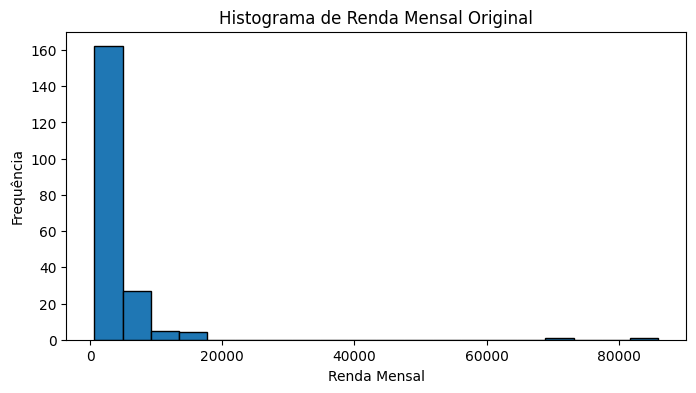

In [21]:
plt.figure(figsize=(8, 4))
plt.hist(df['renda_mensal'], bins=20, edgecolor='black')
plt.title('Histograma de Renda Mensal Original')
plt.xlabel('Renda Mensal')
plt.ylabel('Frequência')
plt.show()

Cria e exibe um histograma simples com 20 divisões (**bins**) para visualizar a distribuição dos valores da renda mensal original.

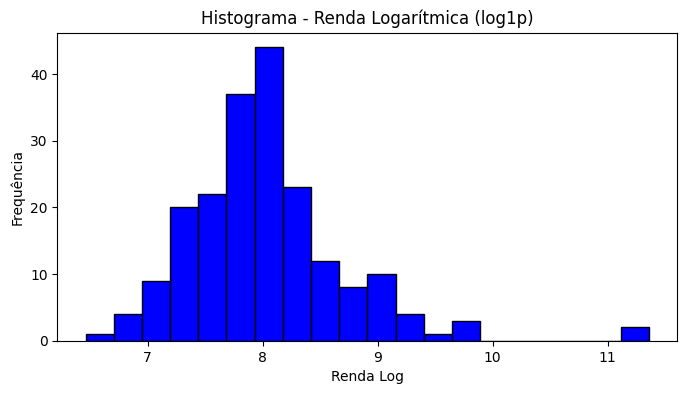

In [24]:
df['renda_log'] = np.log1p(df['renda_mensal'])

plt.figure(figsize=(8, 4))
plt.hist(df['renda_log'], bins=20, edgecolor='black', color='blue')
plt.title('Histograma - Renda Logarítmica (log1p)')
plt.xlabel('Renda Log')
plt.ylabel('Frequência')
plt.show()

Aplica a transformação logarítmica **log(1+x)** **(np.log1p)** na renda para suavizar assimetrias e plota um novo histograma para comparar a diferença na distribuição.

In [25]:
df['faixa_etaria'] = pd.cut(df['idade'], bins = 4)
df['faixa_renda'] = pd.qcut(df['renda_mensal'], q=4)

**pd.cut**: Divide a idade em 4 intervalos baseados na amplitude dos valores (tamanhos de faixa iguais).

------------------------------

**pd.qcut**: Divide a renda em 4 faixas baseadas nos quantis (garantindo que cada faixa contenha aproximadamente a mesma quantidade de clientes).

In [26]:
df['proporcao_gasto'] = df['gasto_mensal'] / df['renda_mensal']

Cria uma nova variável derivada dividindo o gasto mensal pela renda mensal.

# **Parte 5: Normalização e padronização**

In [27]:
X = df[['idade', 'renda_mensal', 'gasto_mensal']]

Seleciona apenas as três colunas numéricas principais que serão utilizadas nos próximos passos de escalonamento e agrupamento.

In [28]:
minmax = MinMaxScaler()
standard = StandardScaler()

X_minmax = minmax.fit_transform(X)
X_standard = standard.fit_transform(X)

Instancia e aplica os transformadores de escala: o **MinMaxScaler** coloca os dados entre 0 e 1, e o **StandardScaler** centraliza os dados na média 0 com desvio padrão 1.

In [30]:
print('\n--- Estatísticas MinMaxScaler ---')
print('Min:', X_minmax.min(axis=0))
print('Max:', X_minmax.max(axis=0))
print('Média:', X_minmax.mean(axis=0))
print('Desvio padrão:', X_minmax.std(axis=0))

print('\n--- Estatísticas StandardScaler ---')
print('Min:', X_standard.min(axis=0))
print('Max:', X_standard.max(axis=0))
print('Média:', X_standard.mean(axis=0))
print('Desvio padrão', X_standard.std(axis=0))


--- Estatísticas MinMaxScaler ---
Min: [0. 0. 0.]
Max: [1. 1. 1.]
Média: [0.50848214 0.04321202 0.05587447]
Desvio padrão: [0.27849666 0.09239182 0.09476239]

--- Estatísticas StandardScaler ---
Min: [-1.82581059 -0.4677039  -0.5896271 ]
Max: [ 1.7648968  10.35576465  9.96308321]
Média: [-8.88178420e-17  2.66453526e-17  1.77635684e-17]
Desvio padrão [1. 1. 1.]


Exibe no console os valores mínimos, máximos, médias e desvios padrão resultantes de cada método para conferência.

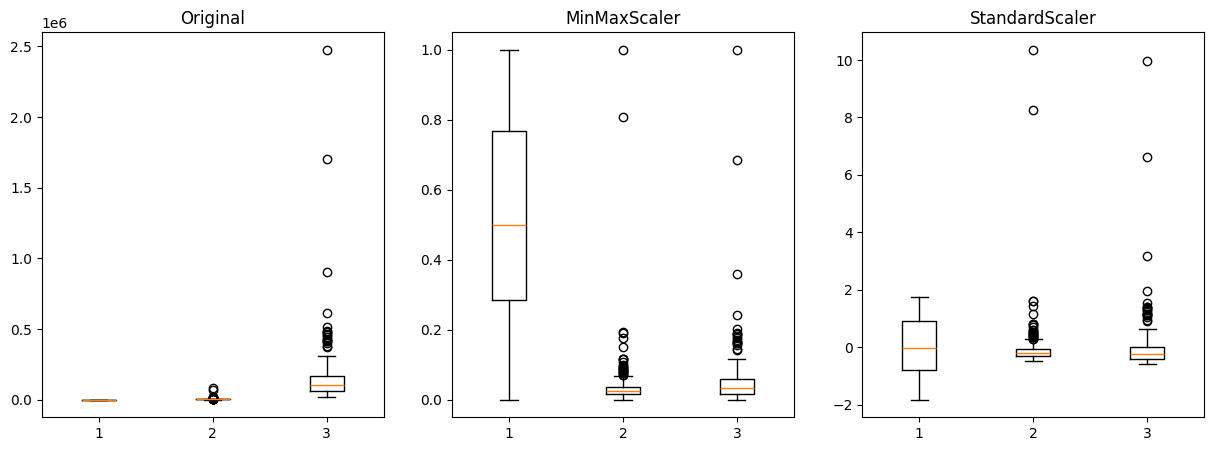

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].boxplot(X.values)
axes[0].set_title('Original')
axes[1].boxplot(X_minmax)
axes[1].set_title('MinMaxScaler')
axes[2].boxplot(X_standard)
axes[2].set_title('StandardScaler')
plt.show()

Plota lado a lado três gráficos de caixa (**boxplots**) para comparar visualmente o impacto dos escalonadores em relação aos dados originais e à presença de outliers.

# **Parte 6: Efeito da escala no agrupamento**

In [32]:
kmenas_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_raw = kmenas_raw.fit_predict(X)

Executa o algoritmo **K-Means** buscando 3 agrupamentos (**n_clusters=3**) diretamente sobre os dados sem escalonar (**X**).

In [35]:
kmeans_std = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_std = kmeans_std.fit_predict(X_standard)

Repete o processo do **K-Means** utilizando agora os dados padronizados (**X_std**) e guarda os rótulos dos grupos gerados em duas novas colunas no DataFrame.

In [38]:
print('\n--- Médias por Grupo(Sem Escalonar) ---')
display(df.groupby(clusters_raw)[['idade', 'renda_mensal', 'gasto_mensal']].mean())

print('\n--- Médias por Grupo(Padronizar) ---')
display(df.groupby(clusters_std)[['idade', 'renda_mensal', 'gasto_mensal']].mean())


--- Médias por Grupo(Sem Escalonar) ---


,idade,renda_mensal,gasto_mensal
0,46.818182,2859.122102,1.029811e+05
1,45.500000,77721.900000,2.088449e+06
2,43.818182,9392.816818,4.314975e+05



--- Médias por Grupo(Padronizar) ---


,idade,renda_mensal,gasto_mensal
0,33.460784,3439.652745,1.366552e+05
1,60.322917,3739.613333,1.424874e+05
2,45.500000,77721.900000,2.088449e+06


Agrupa os dados por cluster e calcula a média de cada atributo para comparar o perfil dos grupos formados antes e depois da padronização.

# **Parte 7: Para ir além**

In [39]:
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

scaler_train = StandardScaler()

X_train_scaled = scaler_train.fit_transform(X_train)
X_test_scaled = scaler_train.transform(X_test)

Separa a base em dados de treino (80%) e teste (20%). Ajusta o **StandardScaler** somente nos dados de treino (**fit_transform**) e aplica essa mesma regra de escala nos dados de teste (**transform**) para evitar o vazamento de dados (data leakage).

In [40]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=3, random_state=42, n_init=10))
])

pipeline.fit(X)
df['cluster_pipeline'] = pipeline.named_steps['kmeans'].labels_

Cria um fluxo automatizado (**Pipeline**) que une a etapa de padronização dos dados com a execução do **K-Means** em um único objeto, treina o conjunto inteiro e extrai os rótulos finais dos clusters gerados.